TokaMaker Example: Breakdown and start-up model validation on DIII-D 200480 {#doc_tMaker_DIIID_ex5}
==========
This example checks the breakdown and start-up model of this folder against a real discharge. It is the
**validation** half of the `Breakdown_Startup` folder; the **optimization** half
(`../optimization/ARC_breakdown_startup_ex.ipynb`, \ref doc_tMaker_ARC_ex4) uses the same model to design an ARC
start-up. It demonstrates:

 - Running the machine and circuit model of the optimization **feed-forward**: the coil currents of a real
   discharge drive the vacuum-vessel eddy currents, with nothing optimized or fitted
 - Comparing the resulting loop voltage with the measurement
 - Checking the breakdown criteria of the optimization (Lloyd criterion, connection length and Townsend avalanche)
   against when and at which pressures DIII-D actually broke down
 - Checking the constraints the optimization puts on its early plasma (force balance, decay index, stray field)
   on the measured plasma current

The discharge is DIII-D shot 200480, the DIII-D reference discharge of the ITPA-IOS multi-machine validation of
the plasma initiation code DYON:

> H.-T. Kim et al., *Multi-machine validation of plasma initiation modelling and prospects for future devices:
> predicting plasma initiation using only hardware design and control room input data*,
> Nucl. Fusion **66** (2026) 036043, [doi:10.1088/1741-4326/ae3caa](https://doi.org/10.1088/1741-4326/ae3caa).

**Runtime:** about 30 seconds on a laptop.

**Prerequisites:** OpenFUSIONToolkit newer than the v26.9 release (the example uses `TokaMaker.setup_model()`)
and the usual scientific Python packages; unlike the optimization, it does not need `clarabel`. The helper
modules `startup_model.py` and `startup_plots.py` one folder up (shared with the optimization) contain the model
and the plotting helpers.

## The validation problem

In a tokamak start-up the central solenoid (on DIII-D, the E coil) is swung, which induces a toroidal electric
field $E_\phi$ in the vessel. If the poloidal field $B_p$ is small enough (a field null), field lines run for
kilometres before they reach the wall, electrons accelerated by $E_\phi$ multiply into an avalanche
(**breakdown**), and a plasma current forms and grows while the plasma heats up (**burn-through**). Every change
of coil current also induces eddy currents in the vacuum vessel, which change both $E_\phi$ and $B_p$.

The optimization designs a start-up with a model of these pieces. Each piece can be tested on a discharge
that has already been run:

| model piece (shared with the optimization) | tested here by |
|---|---|
| vessel cut into segments with $J \propto 1/R$, exact circuit step | the loop voltage the coil currents induce, against the measured loop voltage |
| breakdown: Lloyd criterion $E_\phi B_\phi/B_p \geq E^*$ | whether DIII-D met $E^*$ = 1000 V/m when it broke down |
| breakdown: field-line tracing and Townsend avalanche | the lowest pressure at which the model allows breakdown, against the pressure scan of Kim et al. |
| early plasma: ring channel, Spitzer resistance, prescribed $T_e(t)$ | the plasma current it predicts, against the measured one |
| early plasma: force balance, decay index, stray field | the applied fields at the channel, with the measured plasma current |

### What comes from the DIII-D discharge
The time traces are **approximate trajectories**: piecewise linear between keyframes defined in this notebook
(-20 to 100 ms). They were rounded from the measured signals of 200480 and agree with the traces published in
Kim et al. to within the accuracy of reading those figures.

| trajectory | published in Kim et al. | used as |
|---|---|---|
| E-coil current (6 series circuits, 122 turns) | fig. 1(a) (MA-turns), fig. 4 (OH0-OH5) | **input** |
| F6A/B and F7A/B currents (equal A and B; the other F coils are off until 100 ms) | fig. 4 (too small to read at its scale) | **input** |
| plasma current $I_p$ | fig. 1(d) | **input** in the replay, otherwise **compared** |
| loop voltage measured at the inboard midplane ($R$ = 0.92 m, $Z$ = 0) | figs. 1(c) and 4 | **compared** |
| prefill pressure: 1.4 mPa (DYON effective pressure, 0.25 x the gauge) | fig. 1(b) | Townsend check |
| pressure scan: no breakdown at 0.065 mPa, breakdown at 0.24 mPa (the lowest) | fig. 2 | Townsend check |

The machine geometry comes from two files: `g200480.00100`, the EFIT01 equilibrium of the shot at 100 ms (for
the limiter and the toroidal field), and `../../../DIIID/DIIID_geom.json`, the coils and vacuum vessel of OFT's
DIII-D examples.

### Limitation: no plasma model
The model has **no plasma (burn-through) model**: no electron energy or particle balance, no impurity radiation,
no avalanche growth time. The early plasma is a ring of prescribed position, size and $T_e(t)$ (Spitzer
resistance). So the vessel and the breakdown fields are tested feed-forward, but the plasma current is not
predicted: where the loop voltage needs it, the **measured $I_p$ is replayed**, and the $I_p$ the model predicts
depends directly on the assumed $T_e(t)$. A burn-through model, as in DYON, would be needed to predict the plasma
current and the pressure limits of the operating space.

## Setup Python environment

In [1]:
import os
import sys
import copy
import json
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace          # a light container, used to pass unit currents to field_maps
from matplotlib.colors import LogNorm      # log colour scale for |B_p|
from matplotlib.path import Path           # point-in-polygon tests against the limiter
%matplotlib inline
%config InlineBackend.figure_format = "retina"

## Load TokaMaker library

To load the TokaMaker python module we need to tell python where the module is located. This can be done either
through the `PYTHONPATH` environment variable or within a script using `sys.path.append()` as below, where we look
for the environment variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed
(`/Applications/OFT` on macOS).

We also import the shared start-up modules from the folder above, and the figure style of the folder.

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import gs_Domain
from OpenFUSIONToolkit.TokaMaker.util import read_eqdsk

sys.path.insert(0, '..')    # the shared start-up modules, one folder up
from startup_model import (segment_conductors, MachineModel, ChannelPlasma, feed_forward, eval_fields,
                           FieldTracer, townsend_window, paschen_Emin, Te_burnthrough, MU0)
import startup_plots as splt
plt.rcParams.update(splt.STYLE)             # figure style shared with the optimization's animation
C = splt.COLORS                             # fixed colour order; black is used for measurements

## 1. Machine model

### Load the geometry and the toroidal field

The coils and the vacuum vessel are those of OFT's DIII-D examples (`DIIID_geom.json`, built from EFIT's machine
description): 18 F coils, the E coil, and the vacuum vessel as 28 elements, each with its resistivity $\eta$.

The **E coil** is stored with one entry per turn. Its solenoid winding is graded (the turns are closer together
near the ends), and that sets the E coil's own stray field in the vessel. Breakdown happens in a field null where
large fields nearly cancel, so this detail matters here (a uniform block of turns changes the stray field in the
vessel by up to 20%).

The **limiter** and the vacuum toroidal field $F_0 = R B_\phi$ are those of the shot, read from the EFIT01
equilibrium at 100 ms.

In [3]:
with open('../../../DIIID/DIIID_geom.json') as fid:
    geom = json.load(fid)
eqdsk = read_eqdsk('g200480.00100')
F0 = eqdsk['rcentr'] * eqdsk['bcentr']            # R B_phi [T m], the vacuum toroidal field of the shot
print(f"F coils: {', '.join(k for k in geom['coils'] if not k.startswith('ECOIL'))}")
print(f"E coil: {sum(len(geom['coils'][k]) for k in ('ECOILA', 'ECOILB'))} turns; vessel: {len(geom['vv'])} elements")
print(f'F0 = R B_phi = {F0:.2f} T m')

F coils: F1A, F2A, F3A, F4A, F5A, F6A, F7A, F8A, F9A, F1B, F2B, F3B, F4B, F5B, F6B, F7B, F8B, F9B
E coil: 122 turns; vessel: 28 elements
F0 = R B_phi = -2.98 T m


### Build the mesh

The mesh is built as in the DIII-D meshing example (\ref doc_tMaker_DIIID_ex1), but with the limiter of this shot.
The regions are: the plasma region inside the limiter, the vacuum between the limiter and the vessel, the 28
conducting vessel elements, the coils, and the surrounding air. Each E-coil turn is its own region; the turns are
grouped into two coil sets (ECOILA and ECOILB, 61 turns each) with `coil_set`, so each set has one current. The six
E-coil circuits of DIII-D are in series, so all E-coil turns carry the same current.

In [4]:
# Region types and target resolution [m]
dom = gs_Domain()
dom.define_region('air', 0.08, 'boundary')                           # outside the vessel
dom.define_region('plasma', 0.03, 'plasma')                          # inside the limiter
dom.define_region('vacuum', 0.02, 'vacuum', allow_xpoints=True)      # between the limiter and the vessel
for i, vv in enumerate(geom['vv']):                                  # vessel elements, conducting
    dom.define_region(f'vv{i}', 0.02, 'conductor', eta=vv['eta'])
for key, coil in geom['coils'].items():
    if key.startswith('ECOIL'):                    # E coil: one region per turn, grouped into a coil set
        for i, sub in enumerate(coil):
            dom.define_region(f'{key}_{i}', 0.03, 'coil', coil_set=key, nTurns=sub['nturns'])
    else:                                          # F coils: one region each
        dom.define_region(key, 0.03, 'coil', nTurns=coil['nturns'])

# Geometry of every region
dom.add_polygon(eqdsk['rzlim'][:-1].tolist(), 'plasma', parent_name='vacuum')   # the last point repeats the first
dom.add_enclosed([1.75, 1.25], 'vacuum')                             # a point inside the vacuum region
for i, vv in enumerate(geom['vv']):
    dom.add_polygon(vv['pts'], f'vv{i}', parent_name='air')
for key, coil in geom['coils'].items():
    if key.startswith('ECOIL'):
        for i, sub in enumerate(coil):
            dom.add_polygon(sub['pts'], f'{key}_{i}', parent_name='air')
    else:
        dom.add_polygon(coil['pts'], key, parent_name='air')

# Triangulate, and collect the coil and conductor descriptions TokaMaker needs
mesh_pts, mesh_lc, mesh_reg = dom.build_mesh()
coil_dict, cond_dict = dom.get_coils(), dom.get_conductors()

Assembling regions:


  # of unique points    = 2531
  # of unique segments  = 687


Generating mesh with Triangle:
  # of points  = 19445
  # of cells   = 38688
  # of regions = 171


### Segment the vacuum vessel

As in the optimization, the eddy currents are represented by cutting the conducting structure into segments, each
a 1-turn coil carrying one unknown current with current density $\propto 1/R$ (the distribution a uniform toroidal
electric field drives). The segment resistance follows from the resistivity,
$$ R_{seg} = \frac{2\pi\,\eta}{\sum_{cells} A_{cell}/R_{cell}}. $$
The DIII-D vessel is thin (a few cm), so one segment per vessel element is enough: splitting every element into
three changes the loop voltage and the total vessel current by less than 0.1%.

In [5]:
n_seg = {n: 1 for n in cond_dict if n.startswith('VV')}      # one segment per vessel element
seg_reg, segments, seg_coils, vac_dict = segment_conductors(mesh_pts, mesh_lc, mesh_reg, cond_dict, n_seg,
                                                            center=[1.7, 0.0])
R_seg = np.array([s['R_ohm'] for s in segments])
print(f'{len(segments)} vessel segments, resistance {R_seg.min()*1e3:.1f} to {R_seg.max()*1e3:.1f} milli-Ohm')

28 vessel segments, resistance 1.2 to 29.2 milli-Ohm


### Set up TokaMaker and build the machine model

TokaMaker is set up with the segments as additional coils, so it computes the mutual inductances of coils and
vessel and every field map from its finite-element model. `MachineModel` then collects the mutual-inductance
matrix, the resistances and the vacuum flux of a unit current in every coil set and segment. As a check, the
slowest vessel time constants (the $L/R$ eigenvalues of the vessel on its own) are printed: these are the decay
times of the eddy currents, about 10 ms for DIII-D.

**Note:** Only a single `OFT_env` instance can be used per python kernel, so this class should only be instantiated
**once** in a given Jupyter notebook or python script.

In [6]:
myOFT = OFT_env(nthreads=2)
mygs = TokaMaker(myOFT)
# setup_model modifies the dictionaries it is given, so pass copies
mygs.setup_model(r=mesh_pts, lc=mesh_lc, reg=seg_reg, cond_dict=copy.deepcopy(vac_dict),
                 coil_dict=copy.deepcopy({**coil_dict, **seg_coils}), order=2, F0=F0)
mygs.settings.pm = False                           # silence the per-iteration solver output
mygs.update_settings()
model = MachineModel(mygs, (mesh_pts, mesh_lc, mesh_reg), coil_dict, segments, F0)
nc, nu = model.nc, model.nc + model.ns             # number of coil sets; of all units (coil sets + segments)
print(f'{nc} coil sets + {model.ns} vessel segments')
print('slowest vessel L/R time constants [ms]:', np.round(model.structure_time_constants()[:4] * 1e3, 1))

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        v26.9
Development branch:  tkmr_breakdown
Revision id:         638cac43

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.574E+01
    # of points  =   19445
    # of edges   =   58132
    # of cells   =   38688
    # of boundary points =     200
    # of boundary edges  =     200
    # of boundary cells  =     200
  Resolution statistics:
    hmin =  8.166E-04
    hrms =  3.259E-02
    hmax =  1.197E-01
  Surface grounded at vertex    2502


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1

 Computing flux

 Inverting real matrix
   Time =    5.1739999999999998E-003


computing the vacuum flux of a unit current in each of 48 units ...
20 coil sets + 28 vessel segments
slowest vessel L/R time constants [ms]: [10.8  6.2  3.9  2.7]


## 2. Trajectories of the discharge

### Inputs: the coil currents

The coil currents are given as keyframes (times in ms, per-turn currents in kA). Only the E coil and the outer
vertical-field coils F6 and F7 carry current during breakdown; the other F coils start at 100 ms.

 - **E coil**: held at 59 kA/turn until -10 ms, then swung down. This swing induces the loop voltage. Its 122
   turns carry 7.2 MA-turns at the start, as in Kim et al. fig. 1(a).
 - **F6, F7**: a few hundred A/turn (55 turns each), the vertical field for the plasma's radial force balance.

In [7]:
T_KF = [-20, -10, -6, -2, 0, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]                      # ms
E_COIL = [59.09, 59.09, 58.67, 57.88, 57.46, 56.42, 55.67, 54.09, 52.31, 50.31, 48.38, 46.72,
          45.02, 43.22, 41.64, 39.98]                                                         # kA/turn, all 6 circuits
F6 = [-0.423, -0.432, -0.446, -0.485, -0.501, -0.497, -0.532, -0.633, -0.740, -0.822, -0.922,
      -1.028, -1.145, -1.246, -1.351, -1.445]                                                 # kA/turn, F6A and F6B
F7 = [-0.393, -0.401, -0.414, -0.429, -0.439, -0.528, -0.599, -0.612, -0.832, -0.877, -0.878,
      -0.880, -0.892, -0.897, -0.900, -0.883]                                                 # kA/turn, F7A and F7B

### Measurements to compare with

 - `IP_MEAS`: the plasma current, `[t (ms), I_p (kA)]` (Kim et al. fig. 1(d)). It also drives the "replay" run below.
 - `VLOOP_MEAS`: the loop voltage measured at the inboard midplane, `[t (ms), V]` (Kim et al. figs. 1(c) and 4).
 - The prefill pressure of the shot, and the lower limit of the DIII-D pressure scan (Kim et al. fig. 2). These are
   "effective" pressures, the gauge reading times the factor 0.25 that Kim et al. found from a reference discharge.

In [8]:
IP_MEAS = [[-20, 0], [-10, 1], [-2, 5], [0, 6], [2, 14], [5, 24], [10, 42], [15, 58], [20, 78], [25, 118],
           [30, 153], [35, 177], [40, 192], [50, 229], [60, 271], [70, 311], [80, 345], [90, 381], [100, 413]]   # kA
VLOOP_MEAS = [[-20, 0.0], [-10, 0.0], [-6, 1.3], [-4, 2.7], [-2, 4.3], [0, 5.7], [2, 6.8], [4, 7.3], [6, 7.6],
              [8, 7.4], [10, 7.2], [15, 6.5], [20, 5.9], [25, 5.0], [30, 5.1], [35, 6.0], [40, 6.2], [50, 6.8],
              [60, 6.0], [70, 6.0], [80, 6.6], [90, 6.0], [100, 6.0]]                          # V at R = 0.92 m, Z = 0
P_PREFILL = 1.4e-3                         # Pa, prefill of 200480 (Kim et al. fig. 1(b))
P_FAILED, P_LOWEST_OK = 0.065e-3, 0.24e-3  # Pa, DIII-D scan: no breakdown / lowest with breakdown (Kim et al. fig. 2)

### Interpolate onto the time grid of the model

The model steps every 0.25 ms from -20 ms (where the coil currents are steady and the vessel is at rest) to
100 ms. Each coil set gets its per-turn current in A; both E-coil sets get the E-coil trajectory, and the coils
without a trajectory stay at zero. The **breakdown time** used below is when the measured $I_p$ first exceeds
10 kA.

In [9]:
t = np.arange(-0.020, 0.1001, 2.5e-4)      # s
ms = t * 1e3
kf = lambda tk, v: np.interp(ms, tk, v)    # linear interpolation of keyframes onto the grid
Ic = np.zeros((len(t), nc))                # per-turn current of every coil set [A]
for name in ('ECOILA', 'ECOILB'):
    Ic[:, model.coil_names.index(name)] = kf(T_KF, E_COIL) * 1e3
for names, traj in ((('F6A', 'F6B'), F6), (('F7A', 'F7B'), F7)):
    for name in names:
        Ic[:, model.coil_names.index(name)] = kf(T_KF, traj) * 1e3
Ip_meas = kf(*zip(*IP_MEAS)) * 1e3         # A
V_meas = kf(*zip(*VLOOP_MEAS))             # V
k_bd = np.argmax(Ip_meas > 1.0e4)          # breakdown: first time step with I_p > 10 kA
T_BD = t[k_bd]
print(f'E coil: {E_COIL[0] * 122 / 1e3:.2f} MA-turns at -20 ms, {E_COIL[-1] * 122 / 1e3:.2f} at 100 ms; '
      f'I_p > 10 kA at {T_BD*1e3:.1f} ms')

E coil: 7.21 MA-turns at -20 ms, 4.88 at 100 ms; I_p > 10 kA at 1.0 ms


### Plot the inputs
Top to bottom: the E-coil current, the F6 and F7 currents (in kA-turns), and the measured plasma current. The
dotted line marks the breakdown time.

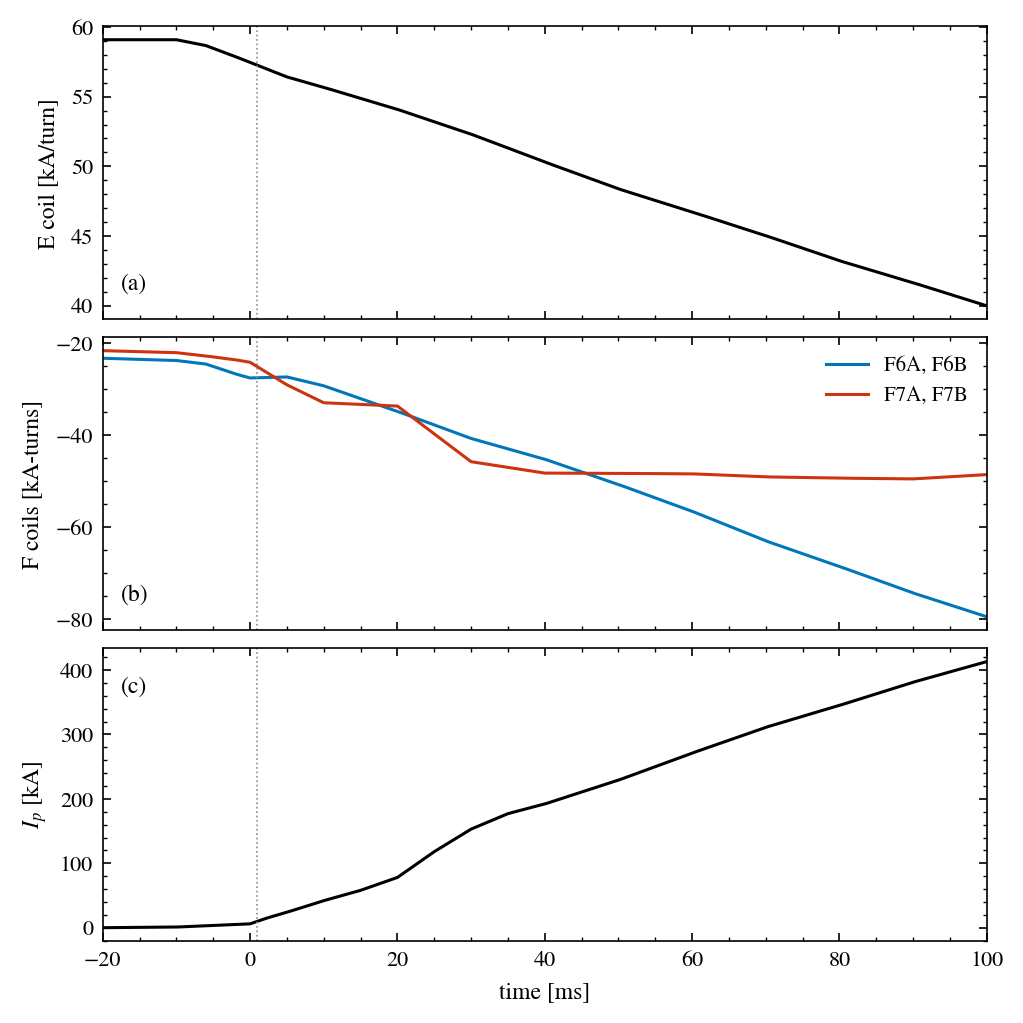

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(5, 5), sharex=True, layout='constrained')
ax[0].plot(ms, kf(T_KF, E_COIL), 'k')
ax[0].set(ylabel='E coil [kA/turn]')
ax[1].plot(ms, kf(T_KF, F6) * 55, color=C[0], label='F6A, F6B')      # 55 turns each
ax[1].plot(ms, kf(T_KF, F7) * 55, color=C[1], label='F7A, F7B')
ax[1].set(ylabel='F coils [kA-turns]')
ax[1].legend(loc='upper right')
ax[2].plot(ms, Ip_meas / 1e3, 'k')
ax[2].set(ylabel='$I_p$ [kA]', xlabel='time [ms]', xlim=(-20, 100))
for a, l in zip(ax, 'abc'):
    a.axvline(T_BD * 1e3, color='0.55', lw=0.6, ls=':')             # breakdown time
    a.text(0.02, 0.1 if l != 'c' else 0.85, f'({l})', transform=a.transAxes)
plt.show()

## 3. Feed-forward circuit: loop voltage and plasma current

In the optimization the supply voltages are the unknowns. Here the coil currents are known, so only the vessel
(and the plasma channel) are unknown. Their circuit equation is
$$ M_{ss}\,\dot{I}_s + R_s\,I_s = -M_{sc}\,\dot{I}_c, $$
where $I_s$ are the segment currents, $I_c$ the coil currents, $M$ the mutual inductances from TokaMaker and $R_s$
the segment resistances. The coil currents are linear between keyframes, so $\dot{I}_c$ is constant on each step
and the equation is integrated **exactly** with the same matrix exponential as the optimization
(`CircuitModel.zoh`). `feed_forward` in `startup_model.py` does this; it returns the currents of all coils,
segments and the plasma channel at every time.

### The early plasma channel

As in the optimization, the early plasma is a ring of uniform current: here the largest circle on the midplane
that fits inside the limiter (inboard-limited, like the DIII-D start-up), with $l_i$ = 0.5 (a flat early current)
and $Z_\mathrm{eff}$ = 2.

In [11]:
wall = max(mygs.lim_contours, key=len)[:, :2]
Rcs = np.linspace(1.2, 2.2, 501)                                              # candidate centres [m]
dist = np.array([np.hypot(wall[:, 0] - r, wall[:, 1]).min() for r in Rcs])   # distance to the wall
Rc, a_ch = Rcs[dist.argmax()], dist.max()                                     # largest circle on the midplane
channel = ChannelPlasma(model, Rc, 0.0, a_ch, li=0.5, Zeff=2.0)
print(f'channel: R = {Rc:.2f} m, a = {a_ch:.2f} m, self-inductance {channel.L_p*1e6:.2f} uH')

channel: R = 1.70 m, a = 0.65 m, self-inductance 2.75 uH


### Four runs

 - **vacuum**: coils and vessel only, no plasma.
 - **replay**: the measured $I_p$ flows in the channel. Its changing flux linkage also drives the vessel. This is
   what the loop voltage needs after breakdown, since the model cannot predict $I_p$.
 - **prediction**: the channel is one more circuit element, $L_p\,\dot{I}_p + R_p I_p + \sum_u M_{pu}\,\dot{I}_u = 0$,
   with the Spitzer resistance $R_p$ at a prescribed $T_e(t)$: 5 eV at breakdown, rising towards 100 eV with time
   constant $\tau$. Two values of $\tau$: 100 ms (the optimization's assumption) and 10 ms. Before breakdown the
   channel is an open circuit (1 k$\Omega$).

In [12]:
runs = {'vacuum': feed_forward(model, t, Ic),                                 # coils and vessel only
        'replay': feed_forward(model, t, Ic, channel, Ip=Ip_meas)}            # measured I_p in the channel
TAUS = (0.1, 0.01)                         # s, burn-through time constants (0.1: the optimization)
for tau in TAUS:
    # channel resistance on each step: Spitzer at the prescribed T_e after breakdown, open circuit before
    Rp = np.where(t[1:] > T_BD, channel.resistance(Te_burnthrough(t[1:], T_BD, tau=tau)), 1.0e3)
    runs[tau] = feed_forward(model, t, Ic, channel, Rp=Rp)                    # I_p predicted

### Compare the loop voltage and the plasma current with the measurements

The loop voltage at a point is $V = -2\pi\, d\psi/dt$, with $\psi$ the flux of all coils, segments and the channel.
It is evaluated where Kim et al. show the measurement, $R$ = 0.92 m on the midplane.

In [13]:
loop = np.array([[0.92, 0.0]])
G = eval_fields(mygs, model.psi_u, loop)['psi'][:, 0]          # flux there per A in every coil set and segment
gp = channel.psi_unit(loop)[0]                                 # ... and per A in the channel
V = {k: -2 * np.pi * np.gradient(X[:, :nu] @ G + X[:, -1] * gp, t) for k, X in runs.items()}
for x in (-0.005, 0.0, 0.005, 0.025, 0.05, 0.1):
    k = np.argmin(abs(t - x))
    print(f'{x*1e3:4.0f} ms: loop voltage measured {V_meas[k]:4.1f} V, '
          f'vacuum {V["vacuum"][k]:4.1f} V, replay {V["replay"][k]:4.1f} V; '
          f'I_p measured {Ip_meas[k]/1e3:4.0f} kA, '
          f'predicted {runs[0.1][k, -1]/1e3:4.0f} (tau 100 ms) / {runs[0.01][k, -1]/1e3:4.0f} kA (tau 10 ms)')

  -5 ms: loop voltage measured  2.0 V, vacuum  5.1 V, replay  4.7 V; I_p measured    4 kA, predicted    0 (tau 100 ms) /    0 kA (tau 10 ms)
   0 ms: loop voltage measured  5.7 V, vacuum  9.0 V, replay  8.5 V; I_p measured    6 kA, predicted    0 (tau 100 ms) /    0 kA (tau 10 ms)
   5 ms: loop voltage measured  7.5 V, vacuum 10.5 V, replay  8.0 V; I_p measured   24 kA, predicted   14 (tau 100 ms) /   24 kA (tau 10 ms)
  25 ms: loop voltage measured  5.0 V, vacuum 10.4 V, replay  3.6 V; I_p measured  118 kA, predicted   63 (tau 100 ms) /  114 kA (tau 10 ms)
  50 ms: loop voltage measured  6.8 V, vacuum 11.4 V, replay  7.2 V; I_p measured  229 kA, predicted  141 (tau 100 ms) /  229 kA (tau 10 ms)
 100 ms: loop voltage measured  6.0 V, vacuum  9.7 V, replay  6.2 V; I_p measured  413 kA, predicted  258 (tau 100 ms) /  384 kA (tau 10 ms)


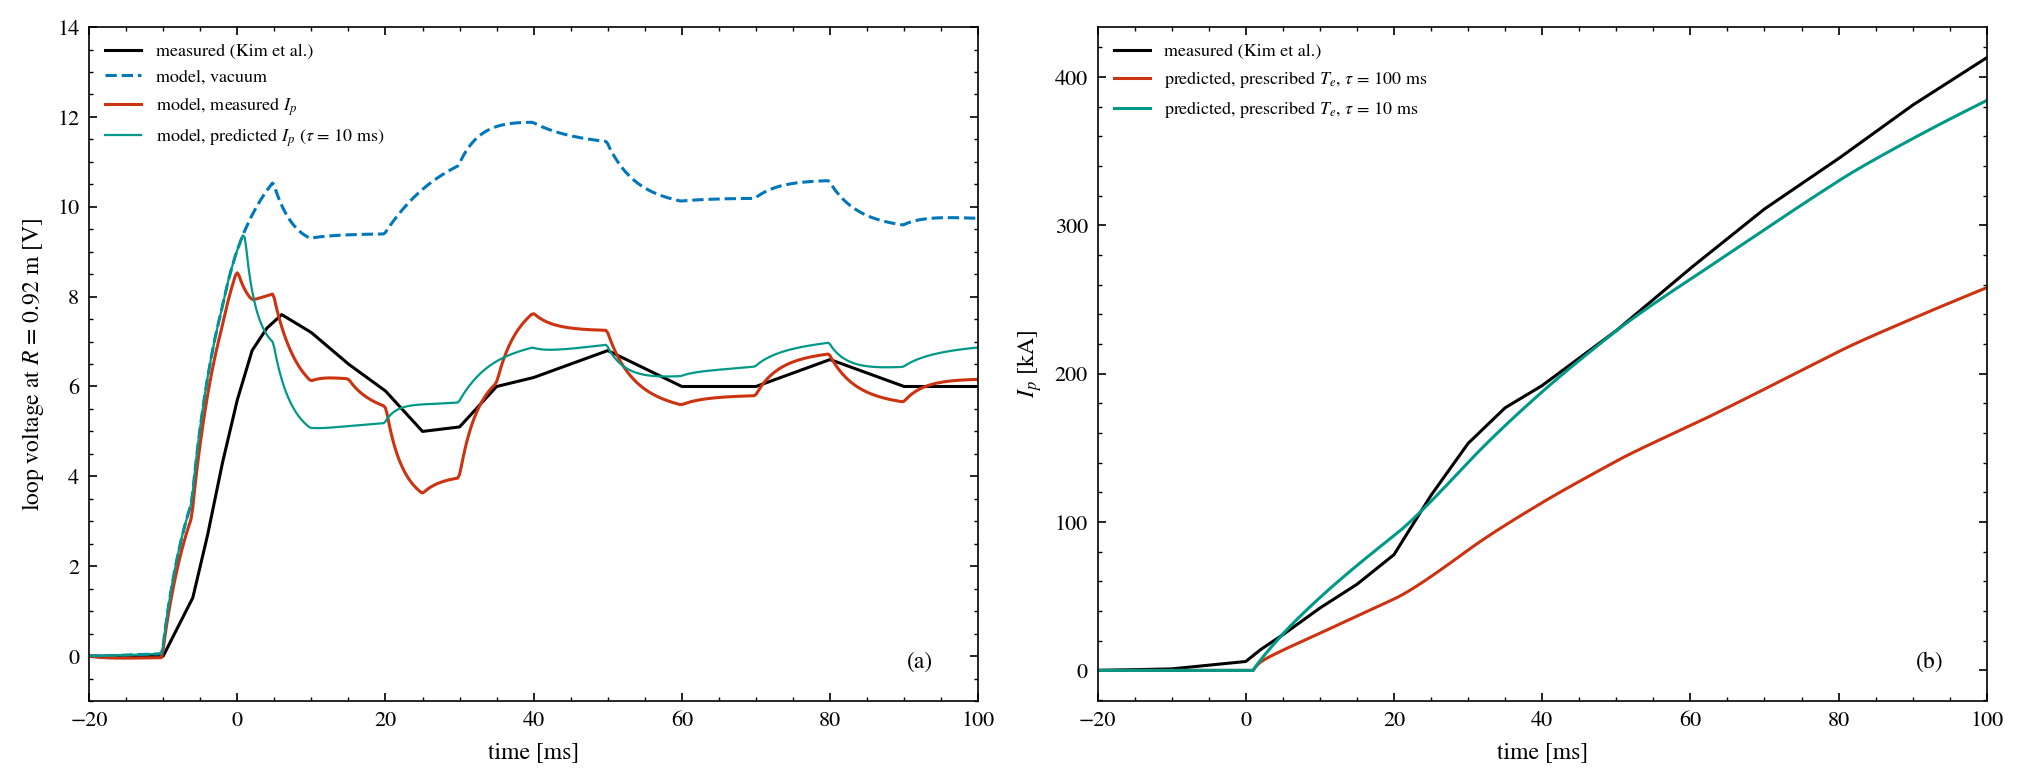

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
a = ax[0]                                                      # (a) loop voltage
a.plot(ms, V_meas, 'k', label='measured (Kim et al.)')
a.plot(ms, V['vacuum'], color=C[0], ls='--', label='model, vacuum')
a.plot(ms, V['replay'], color=C[1], label='model, measured $I_p$')
a.plot(ms, V[0.01], color=C[2], lw=0.8, label=r'model, predicted $I_p$ ($\tau$ = 10 ms)')
a.set(xlabel='time [ms]', ylabel='loop voltage at $R$ = 0.92 m [V]', xlim=(-20, 100), ylim=(-1, 14))
a.legend(loc='upper left', fontsize=6.5)
a = ax[1]                                                      # (b) plasma current
a.plot(ms, Ip_meas / 1e3, 'k', label='measured (Kim et al.)')
for tau, c in zip(TAUS, (C[1], C[2])):
    a.plot(ms, runs[tau][:, -1] / 1e3, color=c, label=rf'predicted, prescribed $T_e$, $\tau$ = {tau*1e3:.0f} ms')
a.set(xlabel='time [ms]', ylabel='$I_p$ [kA]', xlim=(-20, 100))
a.legend(loc='upper left', fontsize=6.5)
for a, l in zip(ax, 'ab'):
    a.text(0.92, 0.05, f'({l})', transform=a.transAxes)
plt.show()

**How to read this figure.**

 - **(a) Loop voltage.** Before breakdown the vacuum model (coils and vessel only) and the measurement rise
   together, the measurement about 3 ms later: the published signal lags the time derivative of the inboard flux
   loops by about 3 ms (that derivative, not shown here, agrees with the vacuum model to about 15% before
   breakdown). After breakdown the plasma current opposes the change of flux, so only the runs that carry a plasma
   current follow the measurement: the replay to within 1.4 V (rms 0.6 V) from 5 ms on, the prediction with
   $\tau$ = 10 ms to within 0.9 V from 20 ms on. The kinks come from the piecewise-linear trajectories.
 - **(b) Plasma current.** With the optimization's $\tau$ = 100 ms the predicted $I_p$ is about 40% low at 50 ms;
   with $\tau$ = 10 ms it is within 16% throughout (equal at 50 ms, 7% low at 100 ms). Without a plasma model this
   is a statement about the assumed $T_e(t)$, not a prediction: DIII-D heated its early plasma faster than the
   optimization assumes for ARC.

## 4. Breakdown: Lloyd criterion

The optimization requires the **Lloyd criterion** over its breakdown region,
$$ \frac{E_\phi\,B_\phi}{B_p} \;\ge\; E^* = 1000\ \text{V/m} $$
(B. Lloyd et al., Nucl. Fusion **31** (1991) 2031). Here it is evaluated on the fields of the vacuum run (coils
and vessel; the plasma current is still small) at the breakdown time, on a grid over the whole vessel. `field_maps`
takes the currents of all coil sets and segments and their time derivatives, and returns $|B_p|$, $E_\phi$, the
flux and the Lloyd quantity on the grid.

In [15]:
X_vac = runs['vacuum']
units = SimpleNamespace(U=np.eye(nu), plasma=None, ip=None)    # field_maps input: the state is the unit currents
dI = np.gradient(X_vac[:, :nu], t, axis=0)                     # dI/dt of every unit, for E_phi = -(dpsi/dt) / R
mp = splt.field_maps(model, units, X_vac[k_bd, :nu], dI[k_bd], 1.0, (0.98, 2.42), (-1.42, 1.42), n=81)
inside = Path(wall).contains_points(np.column_stack([mp['R'].ravel(), mp['Z'].ravel()])).reshape(mp['R'].shape)
lloyd = mp['lloyd'][inside]                                    # only grid points inside the limiter
print(f'at t = {T_BD*1e3:.1f} ms inside the limiter: median E_phi = {np.median(mp["E"][inside]):.2f} V/m, '
      f'median |B_p| = {np.median(mp["Bp"][inside])*1e3:.1f} mT, '
      f'median E B_phi/B_p = {np.median(lloyd):.0f} V/m; >= 1000 V/m over {np.mean(lloyd >= 1000)*100:.0f}% of it')

at t = 1.0 ms inside the limiter: median E_phi = 0.90 V/m, median |B_p| = 2.2 mT, median E B_phi/B_p = 911 V/m; >= 1000 V/m over 41% of it


### Connection length and Townsend avalanche

The Lloyd criterion is an empirical stand-in for the avalanche physics, which can be checked more directly:

 - **Connection length $L_c$.** Follow the magnetic field line (the poloidal field of coils and vessel plus the
   toroidal field $F_0/R$) from each point of a 10 cm grid in both directions until it hits the wall. An electron
   can only multiply over this distance.
 - **Townsend avalanche.** An electron accelerated along the field makes $\alpha = A\,p\,e^{-Bp/E}$ ionisations
   per metre at pressure $p$ (the same hydrogen constants as Kim et al.: $A$ = 3.83 /(m Pa), $B$ = 93.76 V/(m Pa)).
   The avalanche grows when $\alpha L_c \ge 1$. For a given $E_\phi$ and $L_c$ this holds above a lowest pressure,
   computed here for every grid point.

The fraction of grid points that can break down is then compared at the prefill of this shot and at the two
pressures that bracket the lower limit of the DIII-D pressure scan.

In [16]:
tracer = FieldTracer(mygs, model.psi_u.T @ X_vac[k_bd, :nu], F0, wall)
g = np.mgrid[1.05:2.36:0.1, -1.3:1.31:0.1].reshape(2, -1).T                 # 10 cm grid [m]
near_wall = np.hypot(g[:, None, 0] - wall[None, :, 0], g[:, None, 1] - wall[None, :, 1]).min(axis=1) <= 0.04
g = g[Path(wall).contains_points(g) & ~near_wall]                           # inside, more than 4 cm from the wall
Lc = np.array([tracer.connection_length(p) for p in g])                     # m, both directions
E_g = -eval_fields(mygs, (model.psi_u.T @ dI[k_bd])[None], g)['psi'][0] / g[:, 0]   # E_phi at the grid points
# lowest pressure at which each point can break down (alpha L_c >= 1); NaN where no pressure can
p_lo = np.full(len(g), np.nan)
for i, (e, L) in enumerate(zip(E_g, Lc)):
    window = townsend_window(e, L)                                          # (p_min, p_max) [Pa] or None
    if window:
        p_lo[i] = window[0]
print(f'connection length: median {np.median(Lc)/1e3:.1f} km (Kim et al.: L_f = 0.25 a B_phi / B_perp = 292 m)')
print(f'lowest avalanche pressure at the median point: {np.nanmedian(p_lo)*1e3:.2f} mPa')
for lab, p_ in (('prefill of 200480', P_PREFILL), ('lowest pressure with breakdown in the scan', P_LOWEST_OK),
                ('pressure without breakdown in the scan', P_FAILED)):
    print(f'  {lab} ({p_*1e3:.3f} mPa): avalanche possible at {np.mean(p_lo <= p_)*100:.1f}% of the points')

connection length: median 2.2 km (Kim et al.: L_f = 0.25 a B_phi / B_perp = 292 m)
lowest avalanche pressure at the median point: 0.12 mPa
  prefill of 200480 (1.400 mPa): avalanche possible at 93.5% of the points
  lowest pressure with breakdown in the scan (0.240 mPa): avalanche possible at 70.3% of the points
  pressure without breakdown in the scan (0.065 mPa): avalanche possible at 0.4% of the points


### Plot the breakdown conditions
(a) $|B_p|$ of coils and vessel at breakdown, with flux contours (blue) and the contour where the Lloyd criterion is
exactly met (red). (b) The connection length on the grid, with the plasma channel (dashed). (c) The electric field
an avalanche needs, against pressure: breakdown is possible above a curve.

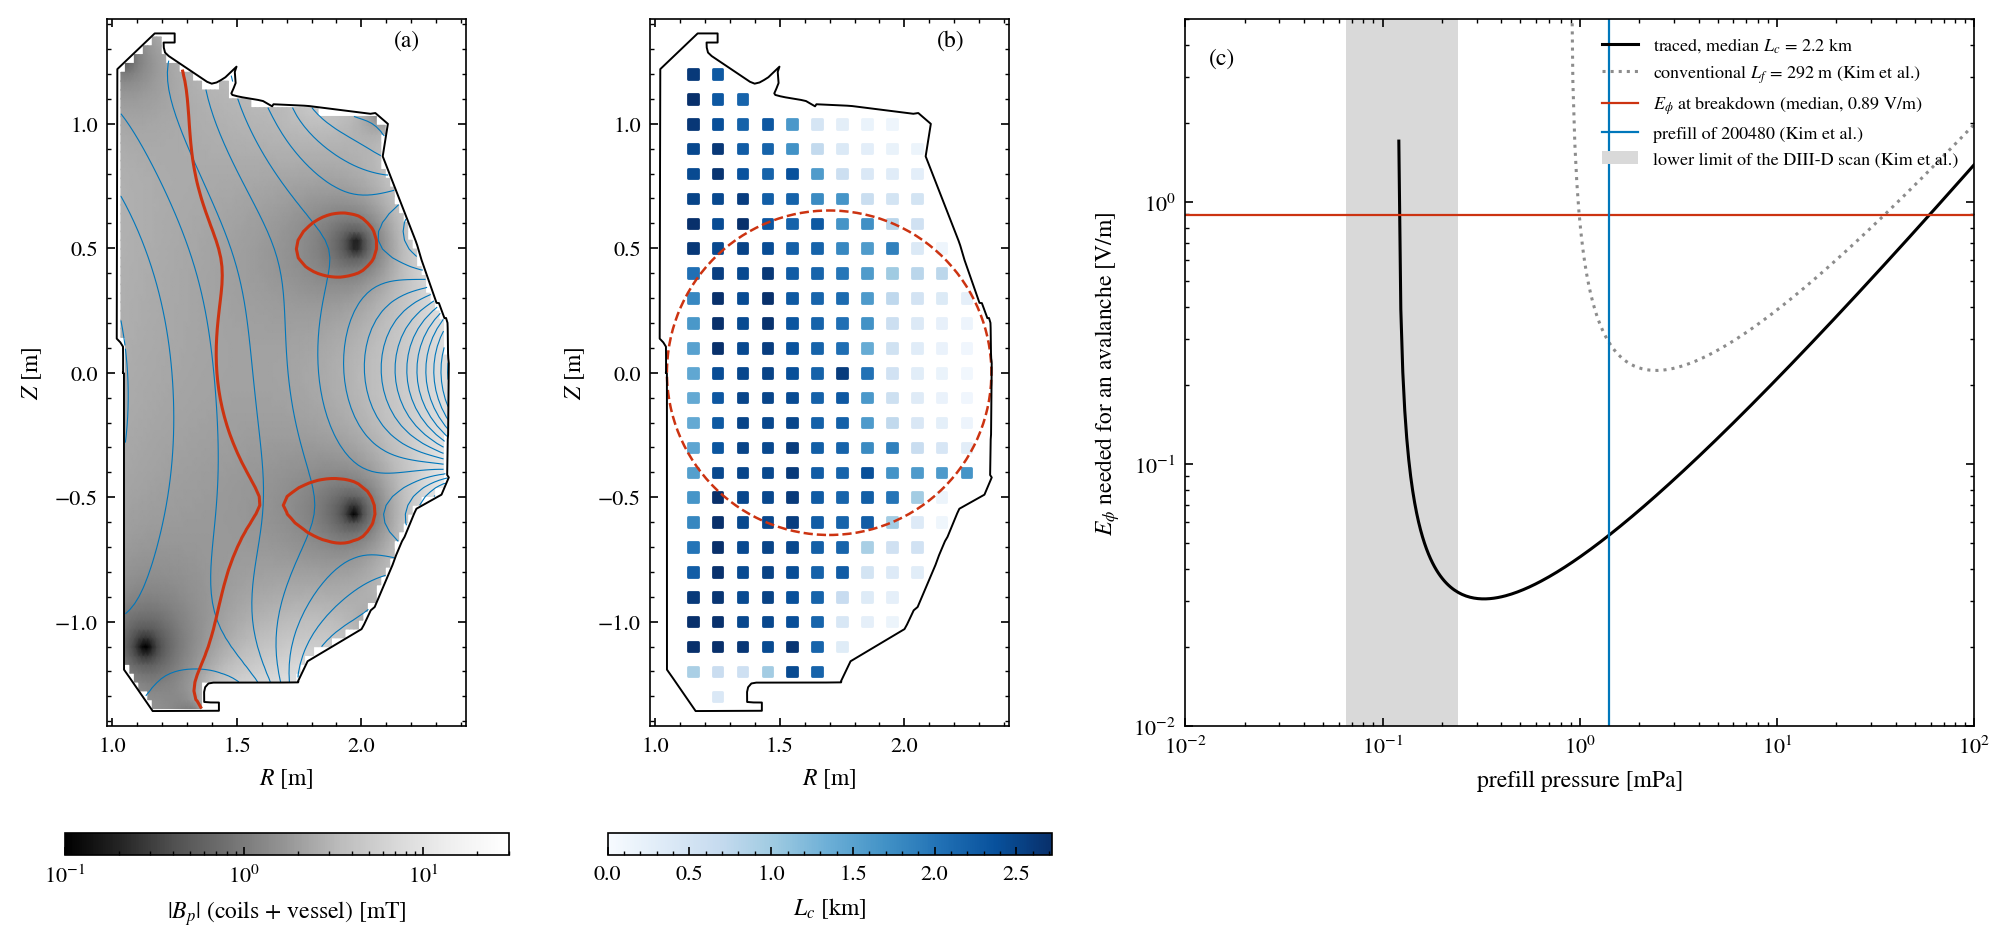

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(10, 4.6), layout='constrained', width_ratios=[1, 1, 1.6])
a = ax[0]                                                      # (a) |B_p| and the Lloyd contour
Bp_in = np.where(inside, mp['Bp'] * 1e3, np.nan)              # mT, blank outside the limiter
h = a.pcolormesh(mp['R'], mp['Z'], Bp_in, norm=LogNorm(0.1, 30), cmap='Greys_r', shading='gouraud')
a.contour(mp['R'], mp['Z'], np.where(inside, mp['psi'], np.nan), 16, colors=C[0], linewidths=0.4)
a.contour(mp['R'], mp['Z'], np.where(inside, mp['lloyd'], np.nan), [1000], colors=C[1], linewidths=1.1)
fig.colorbar(h, ax=a, location='bottom', shrink=0.9, label='$|B_p|$ (coils + vessel) [mT]')
a = ax[1]                                                      # (b) connection length
h = a.scatter(g[:, 0], g[:, 1], c=Lc / 1e3, s=12, marker='s', cmap='Blues', vmin=0, vmax=np.percentile(Lc, 95) / 1e3)
a.add_patch(plt.Circle((Rc, 0), a_ch, fill=False, ec=C[1], ls='--', lw=0.9))
fig.colorbar(h, ax=a, location='bottom', shrink=0.9, label='$L_c$ [km]')
for a in ax[:2]:
    a.plot(wall[:, 0], wall[:, 1], 'k', lw=0.7)
    a.set(aspect='equal', xlim=(0.98, 2.42), ylim=(-1.42, 1.42), xlabel='$R$ [m]', ylabel='$Z$ [m]')
a = ax[2]                                                      # (c) avalanche threshold vs pressure
p = np.logspace(-5, -1, 400)                                   # Pa
a.loglog(p * 1e3, paschen_Emin(p, np.median(Lc)), 'k', label=f'traced, median $L_c$ = {np.median(Lc)/1e3:.1f} km')
a.loglog(p * 1e3, paschen_Emin(p, 292.0), color='0.55', ls=':', label='conventional $L_f$ = 292 m (Kim et al.)')
a.axhline(np.median(E_g), color=C[1], lw=0.8, label=rf'$E_\phi$ at breakdown (median, {np.median(E_g):.2f} V/m)')
a.axvline(P_PREFILL * 1e3, color=C[0], lw=0.8, label='prefill of 200480 (Kim et al.)')
a.axvspan(P_FAILED * 1e3, P_LOWEST_OK * 1e3, color='0.85', lw=0, label='lower limit of the DIII-D scan (Kim et al.)')
a.set(xlabel='prefill pressure [mPa]', ylabel=r'$E_\phi$ needed for an avalanche [V/m]',
      xlim=(1e-2, 1e2), ylim=(1e-2, 5))
a.legend(loc='upper right', fontsize=6.5)
for a, l in zip(ax, 'abc'):
    a.text(0.8 if l != 'c' else 0.03, 0.985 if l != 'c' else 0.96, f'({l})', transform=a.transAxes, va='top')
plt.show()

**How to read this figure.**

 - **(a)** The Lloyd criterion is met on the inboard side and around two weak nulls, about 40% of the vessel; the
   median of $E_\phi B_\phi/B_p$ over the vessel is about 900 V/m. DIII-D broke down anyway, so the optimization's
   requirement of $E^*$ = 1000 V/m over a whole breakdown region is stricter than what DIII-D needed.
 - **(b)** The field lines are kilometres long over most of the vessel, much longer than the conventional
   estimate $L_f = 0.25\,a\,B_\phi/B_\perp$ = 292 m that Kim et al. use for their Paschen curves.
 - **(c)** With the traced $L_c$ the lower pressure limit is about 0.12 mPa, inside the shaded range where the
   DIII-D scan changes from no breakdown (0.065 mPa) to breakdown (0.24 mPa): at 0.065 mPa almost no traced field
   line can avalanche, at 0.24 mPa most can (printed above). The conventional $L_f$ puts the limit near 0.9 mPa,
   above pressures at which DIII-D did break down.

## 5. Early plasma channel: force balance and stray field

The optimization imposes three conditions on its early plasma channel. Here they are evaluated on the fields that
the coils and vessel of the replay run apply at the channel, with the measured $I_p$:

 - **Radial force balance.** The applied vertical field at the centre must hold the ring in place: the Shafranov
   requirement $B_{z,req} = -\mu_0 I_p/(4\pi R)\,(\ln(8R/a) + \beta_p + l_i/2 - 3/2)$, with $\beta_p$ = 0, within the
   optimization's tolerance of 20% + 0.2 mT.
 - **Decay index** $n = -(R/B_z)\, dB_z/dR$ at the centre; the optimization requires $0 \le n \le 1$ (a radially and
   vertically stable field).
 - **Stray field.** Across the channel the applied field differs from the vertical field that force balance needs.
   Until the plasma's own edge field $\mu_0 I_p/(2\pi a)$ is larger than this stray field, the channel has no
   closed flux surfaces.

In [18]:
X = runs['replay']
Gc = eval_fields(mygs, model.psi_u, np.array([[Rc, 0.0]]), second=True)   # per-unit fields at the channel centre
Bz_c = X[:, :nu] @ Gc['Bz'][:, 0]                                          # applied B_z [T]
n_c = -Rc * (X[:, :nu] @ Gc['dBz_dR'][:, 0]) / Bz_c                        # decay index
Bz_req = -MU0 / (4 * np.pi * Rc) * (np.log(8 * Rc / a_ch) + channel.li / 2 - 1.5) * Ip_meas   # Shafranov, beta_p = 0
# stray field: applied field minus the required vertical field, largest over the centre and two rings of points
th = 2 * np.pi * np.arange(16) / 16
p_s = np.vstack([[[Rc, 0.0]]] + [np.column_stack([Rc + r * np.cos(th), r * np.sin(th)]) for r in (0.5 * a_ch, a_ch)])
Gs = eval_fields(mygs, model.psi_u, p_s)
stray = np.hypot(X[:, :nu] @ Gs['Br'], X[:, :nu] @ Gs['Bz'] - Bz_req[:, None]).max(axis=1)
B_own = MU0 * Ip_meas / (2 * np.pi * a_ch)                                 # the plasma's own edge field
for x in (0.02, 0.05, 0.1):
    k = np.argmin(abs(t - x))
    print(f'{x*1e3:3.0f} ms: B_z applied / required {Bz_c[k]/Bz_req[k]:.2f}; decay index {n_c[k]:+.2f}')
print(f'own field > stray field from t = {t[np.argmax((B_own > stray) & (t > T_BD))]*1e3:.0f} ms')

 20 ms: B_z applied / required 1.41; decay index -0.29
 50 ms: B_z applied / required 1.16; decay index -0.21
100 ms: B_z applied / required 1.14; decay index -0.34
own field > stray field from t = 6 ms


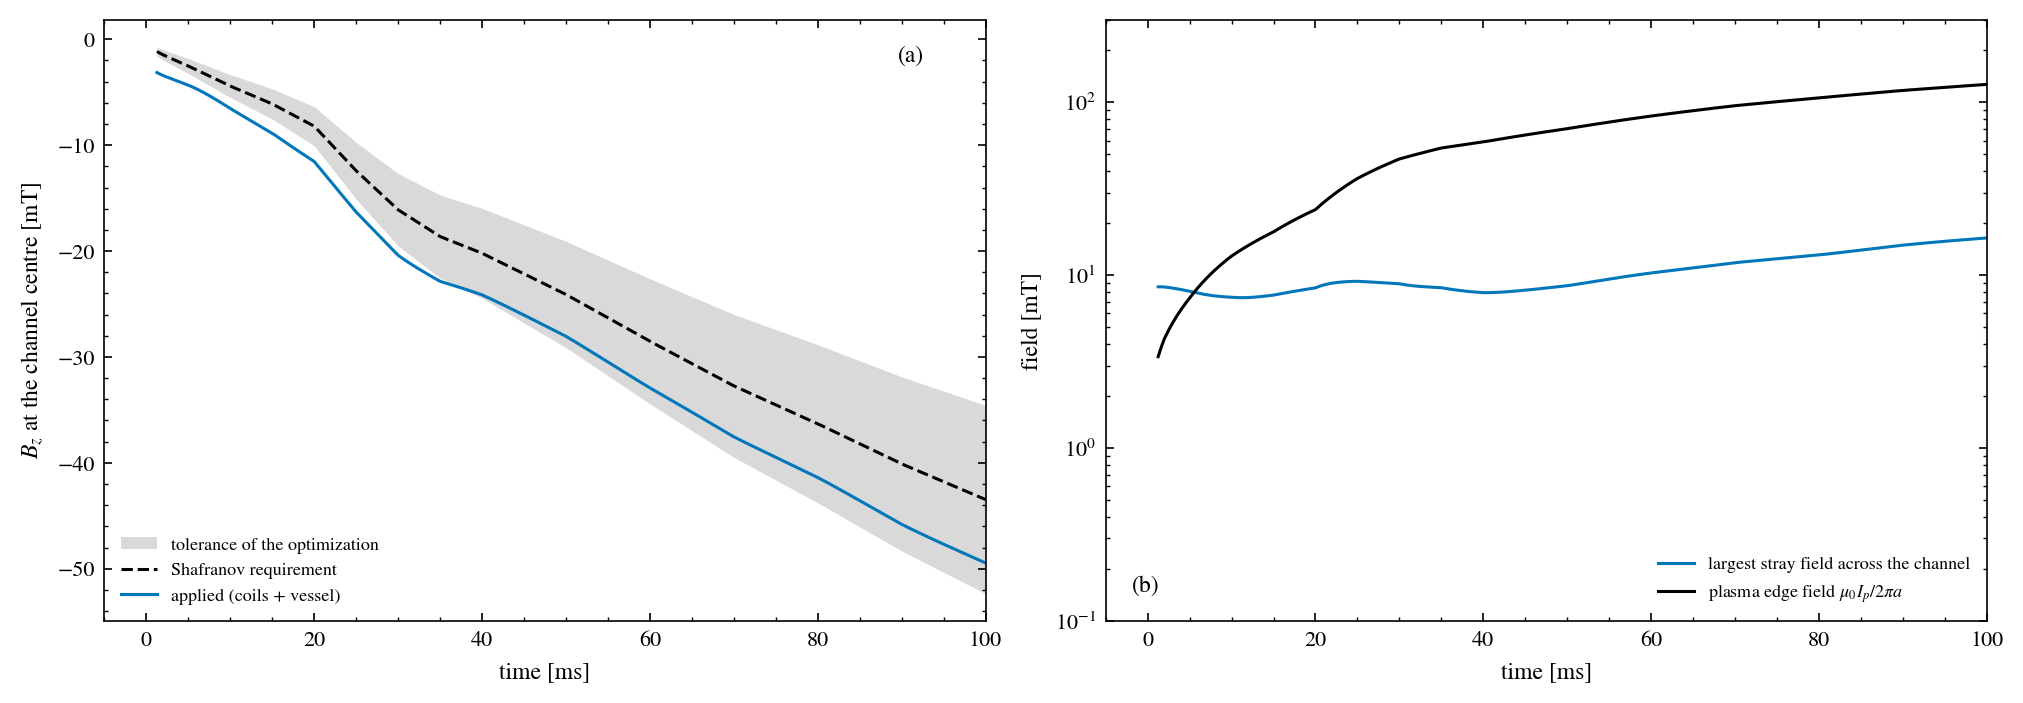

In [19]:
after = t > T_BD                                               # the channel exists after breakdown
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), layout='constrained')
a = ax[0]                                                      # (a) force balance with the optimization's tolerance
tol = 0.2 * np.abs(Bz_req) + 2e-4                              # 20% + 0.2 mT
a.fill_between(ms[after], ((Bz_req - tol) * 1e3)[after], ((Bz_req + tol) * 1e3)[after], color='0.85', lw=0,
               label='tolerance of the optimization')
a.plot(ms[after], (Bz_req * 1e3)[after], 'k--', label='Shafranov requirement')
a.plot(ms[after], (Bz_c * 1e3)[after], color=C[0], label='applied (coils + vessel)')
a.set(ylabel='$B_z$ at the channel centre [mT]')
a.legend(loc='lower left', fontsize=6.5)
a = ax[1]                                                      # (b) stray field vs the plasma's own field
a.plot(ms[after], (stray * 1e3)[after], color=C[0], label='largest stray field across the channel')
a.plot(ms[after], (B_own * 1e3)[after], 'k', label=r'plasma edge field $\mu_0 I_p / 2\pi a$')
a.set(ylabel='field [mT]', yscale='log', ylim=(0.1, 300))
a.legend(loc='lower right', fontsize=6.5)
for a, l in zip(ax, 'ab'):
    a.set(xlabel='time [ms]', xlim=(-5, 100))
    a.text(0.9 if l == 'a' else 0.03, 0.93 if l == 'a' else 0.05, f'({l})', transform=a.transAxes)
plt.show()

**How to read this figure.**

 - **(a)** The applied vertical field is stronger than force balance needs: outside the optimization's tolerance
   until about 37 ms, inside it afterwards. It pushes the plasma onto the inboard limiter, which holds it. The decay
   index printed above is negative (-0.5 to -0.2), outside the 0 to 1 the optimization requires: DIII-D's
   limiter-held start-up does not satisfy that constraint.
 - **(b)** The plasma's own field exceeds the stray field a few ms after breakdown, after which the channel can have
   closed flux surfaces.

## Summary and limitations
- **Reproduced**: the loop voltage, before breakdown from the coil currents and the vessel model alone (allowing
  for the ~3 ms lag of the published signal), and after breakdown once the measured plasma current is included.
- **Consistent**: the Townsend check with traced field lines places the lower pressure limit (about 0.12 mPa)
  between the shot of the DIII-D pressure scan that failed to break down (0.065 mPa) and the lowest one that
  did (0.24 mPa); the conventional estimate (about 0.9 mPa) does not.
- **Conservative**: the optimization's Lloyd threshold (1000 V/m over the region) and decay-index window (0 to 1)
  would both have rejected this successful discharge.
- **Not predicted**: the plasma current. There is no plasma (burn-through) model; $I_p$ follows from an assumed
  $T_e(t)$ and an assumed channel position and size, and the replay uses the measured $I_p$.
- Approximations: piecewise-linear trajectories rounded from the measured traces; the six E-coil circuits are
  taken to carry the same current; the F coils other than F6 and F7 (off until 100 ms, or below 4 kA-turns) are
  zero. Not included: an avalanche growth time (the Townsend criterion is met several ms before $I_p$ rises),
  3-D vessel effects, and the free-boundary ramp (TokaMaker equilibria) of the optimization.